In [1]:
import pandas as pd
%pip install requests python-dotenv
import requests
import os
from dotenv import load_dotenv

load_dotenv()
CLIENT_ID = os.environ["FROST_CLIENT_ID"]


endpoint = 'https://frost.met.no/observations/v0.jsonld'

parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}


r = requests.get(endpoint, parameters, auth=(CLIENT_ID, ''))
json_data = r.json()

if r.status_code == 200:
    data = json_data['data']


    rows = []
    for obs in data:
        time = obs['referenceTime']
        for val in obs['observations']:
            rows.append({'referenceTime': time, 'temperature': val['value']})

    df = pd.DataFrame(rows)
    df['referenceTime'] = pd.to_datetime(df['referenceTime'])

    print("Data ble hentet ut uten feil!")
    print(df.head())
else:
    print(f"Feil oppsto: {r.status_code}")
    print(json_data['error']['reason'])

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\risha\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Data ble hentet ut uten feil!
              referenceTime  temperature
0 2025-01-01 00:00:00+00:00         -5.2
1 2025-01-01 00:00:00+00:00         -2.8
2 2025-01-02 00:00:00+00:00        -11.5
3 2025-01-02 00:00:00+00:00         -7.2
4 2025-01-03 00:00:00+00:00         -8.9


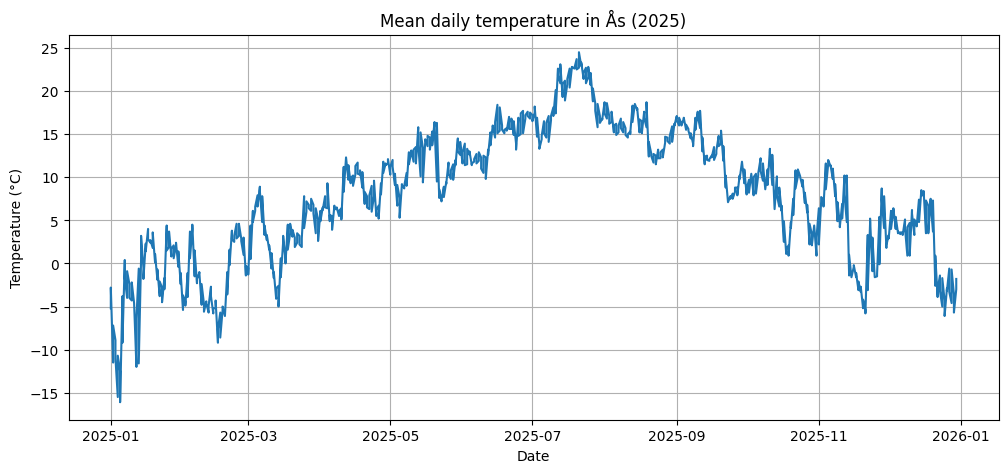

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(df['referenceTime'], df['temperature'], color='tab:blue')
plt.title('Mean daily temperature in Ås (2025)')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.grid(True)
plt.show()

In [3]:
stats = df['temperature'].agg(['mean', 'median', 'min', 'max'])
print("Summary table for air temperature in Ås 2025:")
print(stats)

Summary table for air temperature in Ås 2025:
mean       7.903571
median     8.350000
min      -16.100000
max       24.500000
Name: temperature, dtype: float64


TASK 2

In [4]:

parameters_2 = {
    'sources': 'SN17850',
    'elements': 'sum(precipitation_amount P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

r = requests.get(endpoint, params=parameters_2, auth=(CLIENT_ID, ''))
r.raise_for_status()
data = r.json()['data']

rows_pt6h = []
for obs in data:
    for val in obs['observations']:
        if val['timeOffset'] == 'PT6H':
            rows_pt6h.append({
                'referenceTime': obs['referenceTime'],
                'precipitation': val['value'],
            })

df_precip_pt6h = pd.DataFrame(rows_pt6h, columns=['referenceTime', 'precipitation'])
df_precip_pt6h['referenceTime'] = pd.to_datetime(df_precip_pt6h['referenceTime'])

sum_temp_pt6h = df_precip_pt6h['precipitation'].sum()
print(f"summen for PT6H: {sum_temp_pt6h}")


summen for PT6H: 950.1999999999999


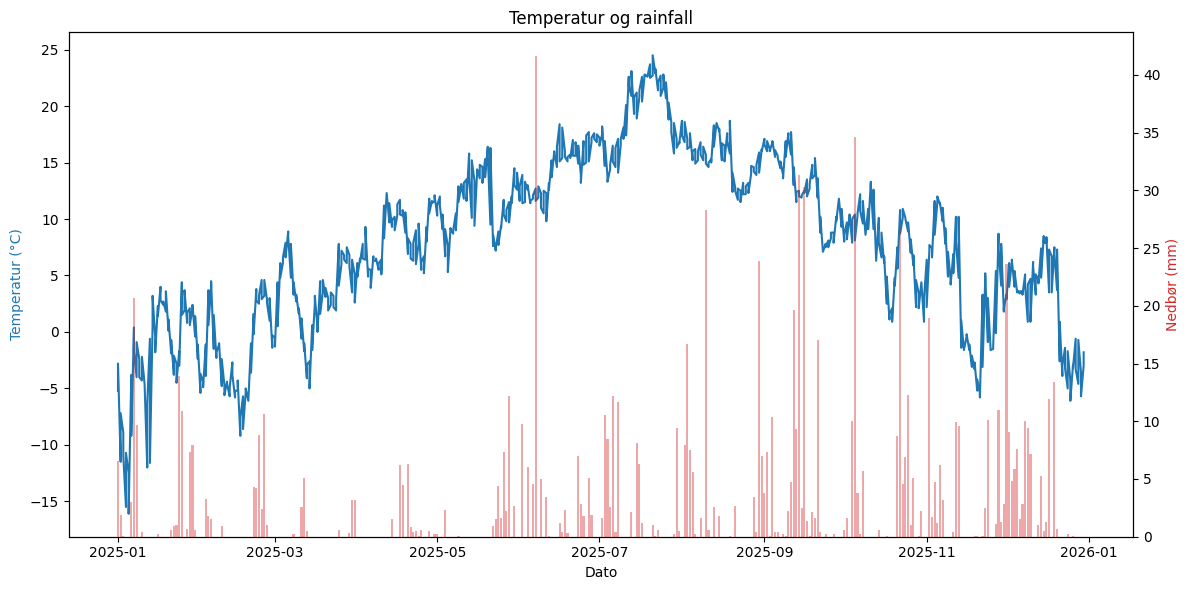

In [5]:
import matplotlib.pyplot as plt

# forklar godt i vid
fig, ax1 = plt.subplots(figsize=(12, 6))

temp_params = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

temp_r = requests.get(endpoint, temp_params, auth=(CLIENT_ID, ''))
temp_json = temp_r.json()

if temp_r.status_code == 200:
    temp_rows = []
    for obs in temp_json['data']:
        for val in obs['observations']:
            temp_rows.append({
                'referenceTime': pd.to_datetime(obs['referenceTime']),
                'temperature': val['value']
            })
    df_temp = pd.DataFrame(temp_rows)
    ax1.plot(df_temp['referenceTime'], df_temp['temperature'], color='tab:blue')
else:
    raise RuntimeError(f"Temperature API error: {temp_r.status_code}")
ax1.set_xlabel('Dato')
ax1.set_ylabel('Temperatur (°C)', color='tab:blue')

ax2 = ax1.twinx()
ax2.bar(
    df_precip_pt6h['referenceTime'],
    df_precip_pt6h['precipitation'],
    color='tab:red',
    alpha=0.4
)
ax2.set_ylabel('Nedbør (mm)', color='tab:red')

ax1.set_title('Temperatur og rainfall')
fig.tight_layout()
plt.show()

Task 3

In [6]:
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import yaml

import os
from dotenv import load_dotenv

load_dotenv()
CLIENT_ID = os.environ["FROST_CLIENT_ID"]
ENDPOINT = "https://frost.met.no/observations/v0.jsonld"
STATION = "SN17850"

plt.rcParams.update({
    "figure.figsize": (11, 5), "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 11,
})


def get_daily(element, start, end, station=STATION):
    """Fetch a daily element from Frost and return a DataFrame with columns time, value."""
    params = {
        "sources": station,
        "elements": element,
        "referencetime": f"{start}/{end}",
    }
    r = requests.get(ENDPOINT, params=params, auth=(CLIENT_ID, ""))
    r.raise_for_status()
    rows = []
    for item in r.json()["data"]:
        for obs in item["observations"]:
            rows.append({"time": item["referenceTime"], "value": obs["value"],
                         "timeOffset": obs.get("timeOffset")})
    df = pd.DataFrame(rows)
    if "PT0H" in df["timeOffset"].values:   # one series per day
        df = df[df["timeOffset"] == "PT0H"]
    df["time"] = pd.to_datetime(df["time"]).dt.tz_localize(None).dt.normalize()
    return df.drop_duplicates("time").sort_values("time").reset_index(drop=True)


def summary_table(series_dict):
    """Mean / median / min / max for one or more named series."""
    out = pd.DataFrame({
        name: {"Mean": s.mean(), "Median": s.median(), "Min": s.min(), "Max": s.max()}
        for name, s in series_dict.items()
    }).round(1)
    out.index.name = "Temperature (°C)"
    return out


def format_dates(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

In [7]:
temp = get_daily("mean(air_temperature P1D)", "2025-01-01", "2025-12-31")
temp.head()

,time,value,timeOffset
0,2025-01-01,-5.2,PT0H
1,2025-01-02,-11.5,PT0H
2,2025-01-03,-8.9,PT0H
3,2025-01-04,-15.5,PT0H
4,2025-01-05,-12.5,PT0H


In [8]:
temp_old = get_daily("mean(air_temperature P1D)", "1925-01-01", "1925-12-31")
print(len(temp_old), "days of data in 1925")

364 days of data in 1925


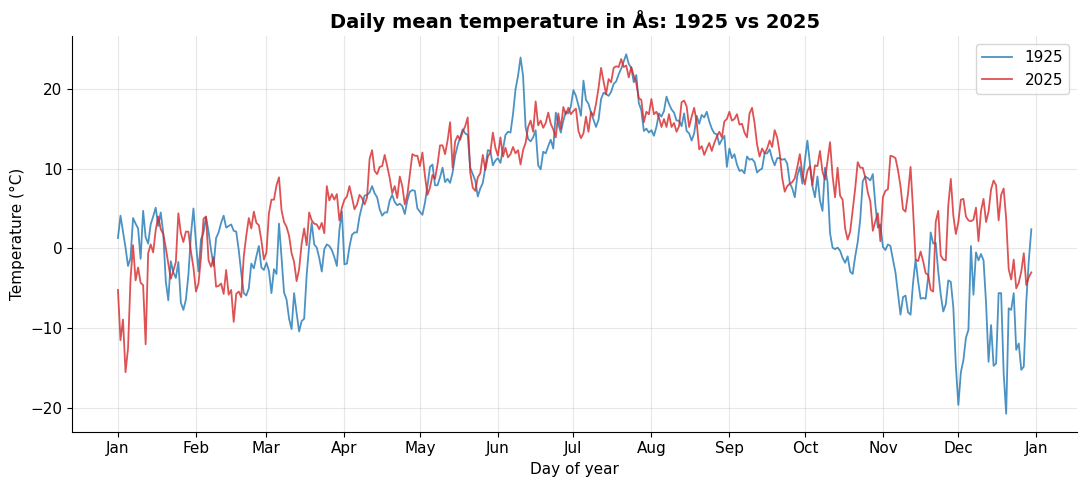

In [9]:
# Put both years on the same calendar axis (both are non-leap years)
old_aligned = temp_old.assign(time=temp_old["time"].map(lambda d: d.replace(year=2025)))

fig, ax = plt.subplots()
ax.plot(old_aligned["time"], old_aligned["value"], color="tab:blue", lw=1.3,
        alpha=0.8, label="1925")
ax.plot(temp["time"], temp["value"], color="tab:red", lw=1.3, alpha=0.8, label="2025")
ax.set_title("Daily mean temperature in Ås: 1925 vs 2025", fontsize=14, weight="bold")
ax.set_xlabel("Day of year")
ax.set_ylabel("Temperature (°C)")
ax.legend()
format_dates(ax)
plt.tight_layout()
plt.show()

In [10]:
print(summary_table({"1925": temp_old["value"], "2025": temp["value"]}).to_string())

                  1925  2025
Temperature (°C)            
Mean               5.3   7.9
Median             5.3   8.4
Min              -20.7 -15.5
Max               24.3  23.7


Task 4

In [11]:
import yaml as yml

heatwave_params = {
    'sources': 'SN17850',
    'elements': 'max(air_temperature P1D)',
    'referencetime': '2023-01-01/2023-12-31',
}


def heatwaves(heatwave_params: dict) -> pd.DataFrame:

    """Creates a dataframe with every heatwave for the given year and creates a summary yml file"""

    heatwave_r = requests.get(endpoint, heatwave_params, auth=(CLIENT_ID, ''))
    heatwave_r.raise_for_status()
    data = heatwave_r.json()["data"]

    heatwave_rows = []

    # if heatwave_r.status_code == 200:
    # data = json_data['data']

    for obs in data:
        for val in obs['observations']:
            if val['elementId'] == 'max(air_temperature P1D)' and val['value'] >= 27.0:
                heatwave_rows.append({

                    'referenceTime': obs['referenceTime'],
                    'heatwave': val['value']
            })

    df_heatwave = pd.DataFrame(heatwave_rows, columns=["referenceTime", "heatwave"])

    records = df_heatwave.to_dict(orient="records")

    with open("heatwaves.yml", "w", encoding="utf-8") as file:
        yml.safe_dump(
        records,
        file,
        allow_unicode=True,
        sort_keys=False,
    )

    return df_heatwave, records


print(heatwaves(heatwave_params))

(               referenceTime  heatwave
0   2023-06-14T00:00:00.000Z      27.8
1   2023-06-14T00:00:00.000Z      27.8
2   2023-06-15T00:00:00.000Z      29.7
3   2023-06-15T00:00:00.000Z      29.7
4   2023-06-16T00:00:00.000Z      30.5
5   2023-06-16T00:00:00.000Z      30.5
6   2023-06-17T00:00:00.000Z      29.7
7   2023-06-17T00:00:00.000Z      29.7
8   2023-06-18T00:00:00.000Z      28.4
9   2023-07-09T00:00:00.000Z      27.0
10  2023-07-09T00:00:00.000Z      27.0, [{'referenceTime': '2023-06-14T00:00:00.000Z', 'heatwave': 27.8}, {'referenceTime': '2023-06-14T00:00:00.000Z', 'heatwave': 27.8}, {'referenceTime': '2023-06-15T00:00:00.000Z', 'heatwave': 29.7}, {'referenceTime': '2023-06-15T00:00:00.000Z', 'heatwave': 29.7}, {'referenceTime': '2023-06-16T00:00:00.000Z', 'heatwave': 30.5}, {'referenceTime': '2023-06-16T00:00:00.000Z', 'heatwave': 30.5}, {'referenceTime': '2023-06-17T00:00:00.000Z', 'heatwave': 29.7}, {'referenceTime': '2023-06-17T00:00:00.000Z', 'heatwave': 29.7}, {'referen

In [12]:
def moving_average(values, window=7):
    return pd.Series(values).rolling(window=window, center=True).mean()

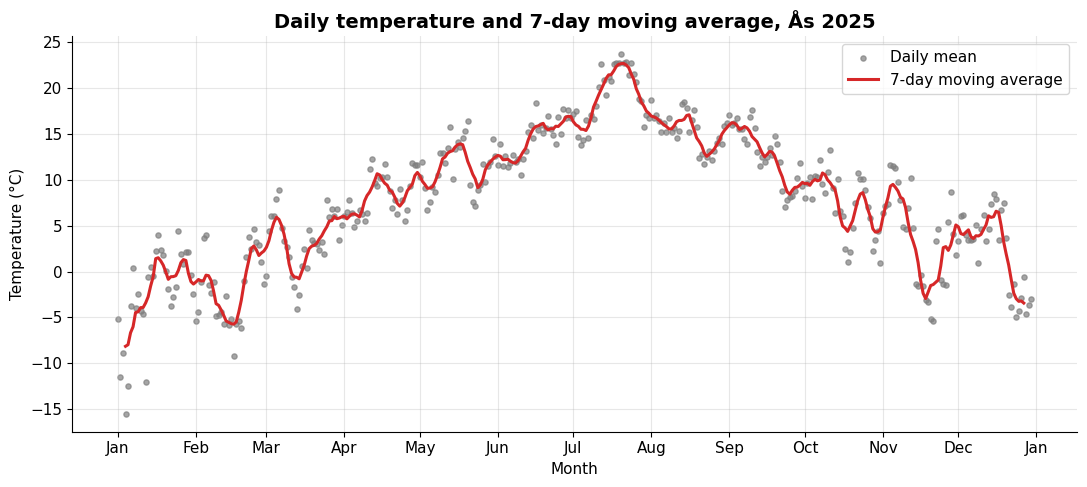

In [13]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df_2025 = temp.rename(columns={"time": "date", "value": "temperature"})[
        ["date", "temperature"]
].copy()
df_2025["ma7"] = moving_average(df_2025["temperature"], window=7)

fig, ax = plt.subplots(figsize=(11, 5))
ax.scatter(df_2025["date"], df_2025["temperature"], s=14, color="tab:gray",
           alpha=0.7, label="Daily mean")
ax.plot(df_2025["date"], df_2025["ma7"], color="tab:red", lw=2.2,
        label="7-day moving average")
ax.set_title("Daily temperature and 7-day moving average, Ås 2025",
             fontsize=14, weight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Temperature (°C)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()